CAPM（资本资产定价模型）

    证券的预期收益只由其 β（对市场组合的敏感度） 决定。

    结论：所有投资者都应该持有市场组合，只是风险厌恶程度不同决定持有多少无风险资产。

CAPM 用于说明：

    如果现实与 CAPM 偏离 → 存在可构建的因子策略（动量、价值等）。

**CAPM (Capital Asset Pricing Model)**

* The expected return of a security is determined solely by its **β (beta)**, which measures its sensitivity to the **market portfolio**.

* **Conclusion:** All investors should hold the **market portfolio**; differences in risk aversion only determine how much they allocate to the **risk-free asset** versus the market.

**CAPM is used to show that:**

* If reality deviates from the predictions of CAPM, then **factor strategies** (such as momentum, value, etc.) can be constructed.




In [3]:
import yfinance as yf
import pandas as pd
import numpy as np
import statsmodels.api as sm

In [4]:
def capm_beta(ticker: str, market: str = "SPY",
              start="2020-01-01", end=None,
              freq="W-FRI", rf_annual=0.0):

    """
    Calculate the CAPM beta of a stock relative to a market index.
    Parameters:
    ticker : str
        The stock ticker symbol.
    market : str
        The market index ticker symbol, such as "SPY", "ACWI", "MSCI World ETF", etc.
    start : str
        The start date for the historical data in "YYYY-MM-DD" format.
    end : str
        The end date for the historical data in "YYYY-MM-DD" format. If None, uses the current date.
    freq : str
        "D" for daily, "W-FRI" for weekly (every Friday), "M" for monthly.
    rf_annual : float   
        The annual risk-free rate as a decimal (e.g., 0.03 for 3%).
    """
    px = yf.download([ticker, market], start=start, end=end, auto_adjust=True)["Close"]
    px = px.dropna()

    # Resample to assigned frequency. Weekly & Monthly are more stable than daily.
    px = px.resample(freq).last()

    # Simple returns
    rets = px.pct_change().dropna()
    ri = rets[ticker]
    rm = rets[market]

    # Annual risk-free rate to periodic
    if freq.startswith("W"):
        periods_per_year = 52  # Weekly
    elif freq.startswith("M"):
        periods_per_year = 12  # Monthly
    else:
        periods_per_year = 252  # Daily

    rf = rf_annual / periods_per_year

    # Excess returns
    excess_i = ri - rf
    excess_m = rm - rf

    X = sm.add_constant(excess_m)
    model = sm.OLS(excess_i, X).fit()


    out = {
        "alpha": model.params["const"],
        "beta": model.params[market] if market in model.params.index else model.params[excess_m.name],
        "t_beta": model.tvalues.iloc[1],
        "r2": model.rsquared,
        "n": int(model.nobs),
    }
    return out, model


In [5]:
stats, model = capm_beta("GOOGL", market="SPY", start="2021-01-01", 
                         freq="W-FRI", rf_annual=0.045)
print(stats)
print(model.summary())

[*********************100%***********************]  2 of 2 completed

{'alpha': np.float64(0.0027296538787674285), 'beta': np.float64(1.1984688641113217), 't_beta': np.float64(12.770596232552109), 'r2': np.float64(0.3863840683118217), 'n': 261}
                            OLS Regression Results                            
Dep. Variable:                  GOOGL   R-squared:                       0.386
Model:                            OLS   Adj. R-squared:                  0.384
Method:                 Least Squares   F-statistic:                     163.1
Date:                Sat, 10 Jan 2026   Prob (F-statistic):           2.70e-29
Time:                        17:58:11   Log-Likelihood:                 513.55
No. Observations:                 261   AIC:                            -1023.
Df Residuals:                     259   BIC:                            -1016.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err   

In [6]:
stats, model = capm_beta("GOOG", market="SPY", start="2021-01-01", 
                         freq="W-FRI", rf_annual=0.045)
print(stats)
print(model.summary())

[*********************100%***********************]  2 of 2 completed

{'alpha': np.float64(0.0027378266005053504), 'beta': np.float64(1.1842216767032212), 't_beta': np.float64(12.597869886117978), 'r2': np.float64(0.3799471444774539), 'n': 261}
                            OLS Regression Results                            
Dep. Variable:                   GOOG   R-squared:                       0.380
Model:                            OLS   Adj. R-squared:                  0.378
Method:                 Least Squares   F-statistic:                     158.7
Date:                Sat, 10 Jan 2026   Prob (F-statistic):           1.05e-28
Time:                        17:58:11   Log-Likelihood:                 513.11
No. Observations:                 261   AIC:                            -1022.
Df Residuals:                     259   BIC:                            -1015.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err   

In [7]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Optional, Union, List, Dict, Any, Tuple

import numpy as np
import pandas as pd
import yfinance as yf
import statsmodels.api as sm
import matplotlib.pyplot as plt


PlotSpec = Union[bool, str, List[str]]


def _periods_per_year(freq: str) -> int:
    f = freq.upper()
    if f.startswith("W"):
        return 52
    if f.startswith("M"):
        return 12
    return 252


def _to_list(plot: PlotSpec) -> List[str]:
    """
    plot:
      False -> []
      True  -> default set
      "all" -> all plots
      "reg" or ["reg","ts"] -> selected
    """
    if plot is False or plot is None:
        return []
    if plot is True:
        return ["reg", "resid", "ts"]  # sensible default
    if isinstance(plot, str):
        if plot.lower() == "all":
            return ["reg", "resid", "ts", "rolling_beta"]
        return [plot.lower()]
    return [p.lower() for p in plot]


def capm_beta(
    ticker: str,
    market: str = "SPY",
    start: str = "2020-01-01",
    end: Optional[str] = None,
    freq: str = "W-FRI",
    rf_annual: float = 0.0,
    *,
    plot: PlotSpec = False,
    rolling_window: Optional[int] = None,
    figsize: Tuple[int, int] = (8, 5),
    title_prefix: str = "",
) -> Tuple[Dict[str, Any], sm.regression.linear_model.RegressionResultsWrapper, Dict[str, plt.Figure]]:
    """
    CAPM beta estimation with optional visualization.

    plot options:
      - False: no plots
      - True: default plots ["reg","resid","ts"]
      - "all": all plots
      - "reg": scatter + fitted line (excess_i vs excess_m)
      - "resid": residual time series + histogram
      - "ts": time series of excess returns (stock & market)
      - "rolling_beta": rolling beta (needs rolling_window or uses heuristic)

    rolling_window:
      - If None and 'rolling_beta' requested: choose window based on freq
        (weekly: 104, monthly: 60, daily: 252)
    """
    # --- Data ---
    px = yf.download([ticker, market], start=start, end=end, auto_adjust=True, progress=False)["Close"]
    px = px.dropna()

    # Resample and drop any empty tail
    px = px.resample(freq).last().dropna()

    # Returns
    rets = px.pct_change().dropna()
    ri = rets[ticker]
    rm = rets[market]

    # Risk-free to period
    ppy = _periods_per_year(freq)
    rf = rf_annual / ppy

    # Excess returns
    excess_i = ri - rf
    excess_m = rm - rf

    # Align & guard
    df = pd.DataFrame({"excess_i": excess_i, "excess_m": excess_m}).dropna()
    if len(df) < 20:
        raise ValueError(f"Too few observations after alignment: n={len(df)}. Check dates/freq/data.")

    # --- Regression ---
    X = sm.add_constant(df["excess_m"])
    model = sm.OLS(df["excess_i"], X).fit()

    out = {
        "alpha": float(model.params["const"]),
        "beta": float(model.params["excess_m"]),
        "t_beta": float(model.tvalues["excess_m"]),
        "r2": float(model.rsquared),
        "n": int(model.nobs),
        "freq": freq,
        "rf_period": float(rf),
    }

    # --- Visualization ---
    figs: Dict[str, plt.Figure] = {}
    plots = _to_list(plot)

    def _make_title(base: str) -> str:
        p = (title_prefix + " ").strip()
        return f"{p}{ticker} vs {market} — {base}"

    # 1) Regression scatter + fit
    if "reg" in plots:
        fig, ax = plt.subplots(figsize=figsize)
        x = df["excess_m"].to_numpy()
        y = df["excess_i"].to_numpy()

        ax.scatter(x, y, alpha=0.6)
        xline = np.linspace(np.nanmin(x), np.nanmax(x), 200)
        yline = out["alpha"] + out["beta"] * xline
        ax.plot(xline, yline)

        ax.set_xlabel(f"{market} excess return")
        ax.set_ylabel(f"{ticker} excess return")
        ax.set_title(_make_title(f"CAPM regression (β={out['beta']:.3f}, R²={out['r2']:.3f})"))
        ax.axhline(0, linewidth=1, alpha=0.3)
        ax.axvline(0, linewidth=1, alpha=0.3)
        figs["reg"] = fig

    # 2) Residual diagnostics: time series + histogram
    if "resid" in plots:
        resid = model.resid
        fig, ax = plt.subplots(figsize=figsize)
        ax.plot(resid.index, resid.values)
        ax.axhline(0, linewidth=1, alpha=0.3)
        ax.set_title(_make_title("Residuals (time series)"))
        ax.set_xlabel("Date")
        ax.set_ylabel("Residual")
        figs["resid_ts"] = fig

        fig, ax = plt.subplots(figsize=figsize)
        ax.hist(resid.values, bins=40)
        ax.set_title(_make_title("Residuals (histogram)"))
        ax.set_xlabel("Residual")
        ax.set_ylabel("Count")
        figs["resid_hist"] = fig

    # 3) Excess returns time series (stock & market)
    if "ts" in plots:
        fig, ax = plt.subplots(figsize=figsize)
        ax.plot(df.index, df["excess_i"], label=f"{ticker} excess")
        ax.plot(df.index, df["excess_m"], label=f"{market} excess")
        ax.axhline(0, linewidth=1, alpha=0.3)
        ax.set_title(_make_title("Excess returns (time series)"))
        ax.set_xlabel("Date")
        ax.set_ylabel("Return")
        ax.legend()
        figs["ts"] = fig

    # 4) Rolling beta (stability check)
    if "rolling_beta" in plots:
        if rolling_window is None:
            # heuristic defaults
            if freq.upper().startswith("W"):
                rolling_window = 104  # ~2y weekly
            elif freq.upper().startswith("M"):
                rolling_window = 60   # ~5y monthly
            else:
                rolling_window = 252  # ~1y daily

        # rolling OLS slope via cov/var (fast and identical to OLS slope with intercept)
        x = df["excess_m"]
        y = df["excess_i"]
        cov_xy = y.rolling(rolling_window).cov(x)
        var_x = x.rolling(rolling_window).var()
        beta_roll = cov_xy / var_x

        fig, ax = plt.subplots(figsize=figsize)
        ax.plot(beta_roll.index, beta_roll.values)
        ax.axhline(out["beta"], linewidth=1, alpha=0.3)
        ax.set_title(_make_title(f"Rolling β (window={rolling_window})"))
        ax.set_xlabel("Date")
        ax.set_ylabel("Beta")
        figs["rolling_beta"] = fig

    return out, model, figs


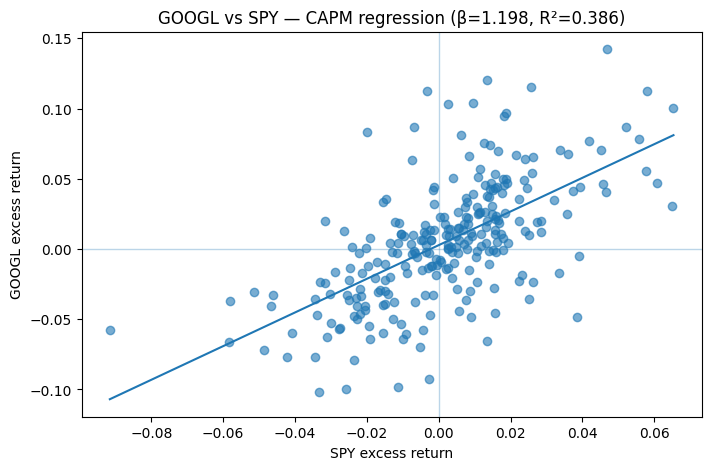

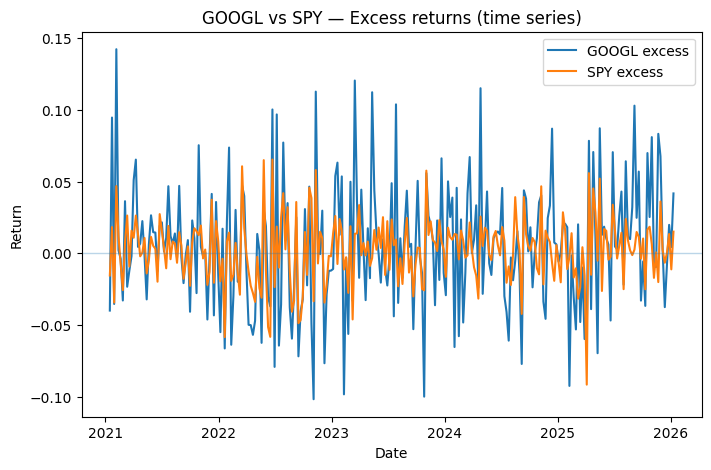

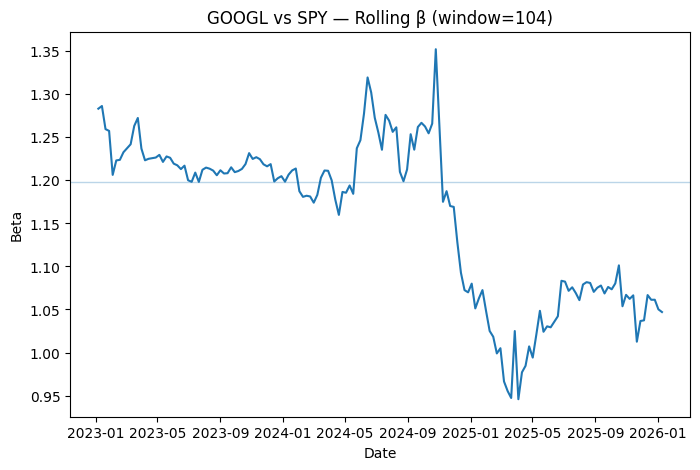

: 

In [ ]:
stats, model, figs = capm_beta(
    "GOOGL", market="SPY", start="2021-01-01",
    freq="W-FRI", rf_annual=0.045,
    plot=["reg", "ts", "rolling_beta"],
    rolling_window=104
)

# 保存图
for k, fig in figs.items():
    fig.savefig(f"{k}.png", dpi=150, bbox_inches="tight")
